In [162]:
import pandas as pd
import geopandas as gpd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
import math
import openpyxl

In [163]:
gdf_2022 = gpd.read_file('2022data.shp')
gdf_2022 = gdf_2022.to_crs("32718")

In [164]:
df_water_2024 = pd.read_excel('2024_full_data.xls')

In [165]:
df_water_2024.columns

Index(['OBJECTID', 'Join_Count', 'TARGET_FID', 'Speed_km_h',
       'Direction_of_travel', 'Compass_reading', 'Position_source_type',
       'Receiver_Name', 'Horizontal_Accuracy_m', 'Vertical_Accuracy_m',
       'Latitude', 'Longitude', 'Altitude', 'PDOP', 'HDOP', 'VDOP', 'Fix_Type',
       'Correction_Age', 'Station_ID', 'Number_of_Satellites', 'Fix_Time',
       'Average_Horizontal_Accuracy_m', 'Average_Vertical_Accuracy_m',
       'Averaged_Positions', 'Standard_Deviation_m', 'CreationDate', 'Creator',
       'EditDate', 'Editor', 'Additional_observations', 'Land_use_type',
       'Land_use_description', 'Underlying_geological_feature',
       'Underlying_geomorphological_feature_legend_code',
       'Complete_soil_description', 'Soil_code_abbreviation', 'Soil_type',
       'Altitude_1', 'Slope_angle', 'Data_point_number', 'Date_and_time',
       'AREA', 'PERIMETER', 'GEOLOGIA', 'GEOLOGIA_I', 'CODI', 'NAME', 'HPI',
       'CNA', 'VER', 'CAL', 'CA1', 'CON', 'HP', 'CAR', 'MAP', 'CMY'

There are X and Y coordinates for the location of points, I'm gonna use that to make a geodataframe. I don't have access to any kind of
.gpkg or .shp file for the 2024 data so relying on this CSV will have to do

In [166]:
gdf_2024 = gpd.GeoDataFrame(
    df_water_2024,
    geometry=gpd.points_from_xy(df_water_2024["Latitude"], df_water_2024["Longitude"]),
    crs='EPSG:32718',
).to_crs("32718")

In [167]:
gdf_2026 = gpd.read_file('2026_water_samples_geo.gpkg').to_crs("32718")

/Users/Sari/Documents/Code/watergroup/venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: Non-conformant content for record 1 in column CreationDate, 2026-06-14T17:25:28.0Z, successfully parsed
  return ogr_read(


In [168]:
lab_results_2026 = pd.read_csv('2026_lab_results.csv')

In [169]:
gdf_2026 = gdf_2026.merge(
    lab_results_2026,
    left_on=('ID'),
    right_on=('Sample'),
)

In [170]:
gdf_2026 = gdf_2026.drop(columns='Sample')

In [171]:
# simplifying some column names for 2026
gdf_2026 = gdf_2026.rename(columns={
    "Tree_cover": "tree_cover", 
    "Shrubs_cover": "shrub_cover", 
    "SucculentsCacti_cover": "succulent_cover",
    "Grasses_cover": "grass_cover",
    "Herbaceous_plant_cover": "herbaceous_cover",
    "Bare_cover": "bare_cover",
    "Electrical_Conductivity": "EC",
    'Al\n(mg/L)': 'Al',
    'As\n(mg/L)': 'As',
    'Ba\n(mg/L)': 'Ba',
    'Ca\n(mg/L)': 'Ca',
    'Cd\n(mg/L)': 'Cd',
    'Cu\n(mg/L)': 'Cu',
    'Fe\n(mg/L)': 'Fe',
    'K\n(mg/L)': 'K',
    'Mg\n(mg/L)': 'Mg',
    'Na\n(mg/L)': 'Na',
    'Pb\n(mg/L)': 'Pb',
    'S\n(mg/L)': 'S',
})

In [172]:
# more simplifying and standardising names for all the years...

candidates = {
    'EC':   ['EC__µS_cm', 'EC', 'EC_1', 'Electrical_Conductivity'],
    'pH':   ['pH', 'pH_1'],
    'Temp': ['Temperatur', 'Temp', 'Temp_1', 'Water_Temperature'],
    'NO3':  ['NO3', 'NO3_mg_L'],
    'PO4':  ['PO4', 'PO42', 'PO4_mg_L'],
    'Cl':   ['Cl'],
    'SO4':  ['SO4'],
    'Al':   ['Al', 'Al_mg_L', 'Al\n(mg/L)'],
    'As':   ['As', 'As_mg_L', 'As\n(mg/L)'],
    'Ba':   ['Ba', 'Ba_mg_L', 'Ba\n(mg/L)'],
    'Ca':   ['Ca', 'Ca_mg_L', 'Ca\n(mg/L)'],
    'Cd':   ['Cd', 'Cd_mg_L', 'Cd\n(mg/L)'],
    'Cu':   ['Cu', 'Cu_mg_L', 'Cu\n(mg/L)'],
    'Fe':   ['Fe_', 'Fe', 'Fe_mg_L', 'Fe\n(mg/L)'],
    'K':    ['K_', 'K', 'K_mg_L', 'K\n(mg/L)'],
    'Mg':   ['Mg_', 'Mg', 'Mg_mg_L', 'Mg\n(mg/L)'],
    'Mn':   ['Mn_', 'Mn_mg_L', 'Mn\n(mg/L)'],
    'Na':   ['Na_', 'Na', 'Na_mg_L', 'Na\n(mg/L)'],
    'Pb':   ['Pb', 'Pb_mg_L', 'Pb\n(mg/L)'],
}


def standardise(gdf, candidates, year):
    rename = {}
    for std, variants in candidates.items():
        found = [c for c in variants if c in gdf.columns]
        if len(found) > 1:
            print(f'{year}: {std} matches several columns {found}, keeping first, check these')
        if found:
            rename[found[0]] = std
    return gdf.rename(columns=rename)

In [173]:
gdf_2022 = standardise(gdf_2022, candidates, 2022)
gdf_2024 = standardise(gdf_2024, candidates, 2024)
gdf_2026 = standardise(gdf_2026, candidates, 2026)

2024: EC matches several columns ['EC', 'EC_1'], keeping first, check these
2024: pH matches several columns ['pH', 'pH_1'], keeping first, check these
2024: Temp matches several columns ['Temp', 'Temp_1'], keeping first, check these
2024: PO4 matches several columns ['PO42', 'PO4_mg_L'], keeping first, check these


In [174]:
element_cols = ['Al', 'As', 'Ba', 'Ca', 'Cd', 'Cu', 'Fe', 'K', 'Mg', 'Na', 'Pb', 'S']
vegetation_cover_columns = ['tree_cover', 'shrub_cover', 'succulent_cover', 'grass_cover', 'herbaceous_cover', 'bare_cover']

In [175]:
# so we entered the data in a little bit of an insane way.
# For some samples, we did observe vegetation surrounding the sample. For these, if a category had 0% cover, we either entered a 0 value,
# or no value at all (a NaN).
# for the samples where we didn't collect anything, every category for vegetation cover is a NaN
# I can't just make all NaNs 0, because it would be wrong: we just don't have data for some of these, so they aren't 0. They would
# mess up any model we might make. but I also need to replace the NaNs with 0s on the data points we DID collect but didn't input a 0 in

In [176]:
# checks if any of the veg cover values isn't a NaN across each row
measured_vegetation = gdf_2026[vegetation_cover_columns].notna().any(axis=1)
gdf_2026['measured_vegetation'] = measured_vegetation
gdf_2026.loc[measured_vegetation, vegetation_cover_columns] = (
    gdf_2026.loc[measured_vegetation, vegetation_cover_columns].fillna(0)
)

In [177]:
df_measured_vegetation = gdf_2026[measured_vegetation].copy()

In [178]:
df_measured_vegetation[vegetation_cover_columns].sum(axis=1) - df_measured_vegetation['bare_cover']

0      58.0
2     109.0
5      43.0
6      64.0
16    115.0
19     86.0
22     93.0
61    141.0
63     95.0
72     44.0
73     80.0
76     94.0
dtype: float64

In [179]:
measured_vegetation = gdf_2026[vegetation_cover_columns].notna().any(axis=1)
gdf_2026.index[measured_vegetation].tolist()

[0, 2, 5, 6, 16, 19, 22, 61, 63, 72, 73, 76]

In [180]:
df_all_years_by_area = pd.read_csv('data_by_year_and_area.csv')

In [181]:
df_all_years_by_area['label'] = df_all_years_by_area['year'].astype(str) + df_all_years_by_area['ID']

In [182]:
df_all_years_by_area['label']

0       2022061`
1        2026124
2         2024E1
3        2026127
4        2026126
         ...    
181      2026136
182    20221A071
183      2026102
184     2022033`
185       2024H1
Name: label, Length: 186, dtype: str

In [183]:
for index, label in enumerate(df_all_years_by_area['label']):
    # for occult Excel sheet reasons, a  character exists at the end of certain labels and must be removed
    if label.endswith("`"):
        df_all_years_by_area.at[index, 'label'] = label[:-1]

In [184]:
gdf_2022['label'] = '2022' + gdf_2022['Obs_number']
gdf_2024['label'] = '2024' + gdf_2024['SampleID'].astype(str)
gdf_2026['label'] = '2026' + gdf_2026['ID']

In [185]:
gdf_2026['low_cover'] = (
    gdf_2026['herbaceous_cover'] 
    + gdf_2026['grass_cover']
    + gdf_2026['succulent_cover']
)

In [186]:
gdf_2026['high_cover'] = (
    gdf_2026['tree_cover']
    + gdf_2026['shrub_cover']
)

In [187]:
gdf_all_years = pd.concat([gdf_2022, gdf_2024, gdf_2026], ignore_index=True)

df_all_years_by_area = df_all_years_by_area.merge(
    gdf_all_years,
    on='label'
)



In [188]:
# check which measures we have in every single year
measures_2022 = set(gdf_2022.columns)
measures_2024 = set(gdf_2024.columns)
measures_2026 = set(gdf_2026.columns)
measures_all_years = set.intersection(measures_2022, measures_2024, measures_2026)
measures_all_years

{'Al',
 'Ba',
 'Ca',
 'Cu',
 'EC',
 'Fe',
 'K',
 'Mg',
 'Na',
 'Temp',
 'geometry',
 'label',
 'pH'}

In [189]:
columns_of_interest = sorted({'Al', 'As', 'Ba', 'Ca', 'Cu', 'EC', 'Fe', 'K', 'Mg', 'Na', 'pH'})

In [190]:
df_comparison_data =  df_all_years_by_area.copy()
df_comparison_data[columns_of_interest] = df_comparison_data[columns_of_interest].apply(pd.to_numeric, errors='coerce')

In [191]:
df_summary_comparison = (
    df_comparison_data.groupby(['group', 'year'])[columns_of_interest]
      .agg(['mean', 'median', 'std', 'count'])
)

# flatten ('pH', 'mean') -> 'mean_pH'
df_summary_comparison.columns = [f'{stat}_{col}' for col, stat in df_summary_comparison.columns]
df_summary_comparison = df_summary_comparison.reset_index()

In [210]:
df_summary_comparison.columns

Index(['group', 'year', 'mean_Al', 'median_Al', 'std_Al', 'count_Al',
       'mean_As', 'median_As', 'std_As', 'count_As', 'mean_Ba', 'median_Ba',
       'std_Ba', 'count_Ba', 'mean_Ca', 'median_Ca', 'std_Ca', 'count_Ca',
       'mean_Cu', 'median_Cu', 'std_Cu', 'count_Cu', 'mean_EC', 'median_EC',
       'std_EC', 'count_EC', 'mean_Fe', 'median_Fe', 'std_Fe', 'count_Fe',
       'mean_K', 'median_K', 'std_K', 'count_K', 'mean_Mg', 'median_Mg',
       'std_Mg', 'count_Mg', 'mean_Na', 'median_Na', 'std_Na', 'count_Na',
       'mean_pH', 'median_pH', 'std_pH', 'count_pH'],
      dtype='str')

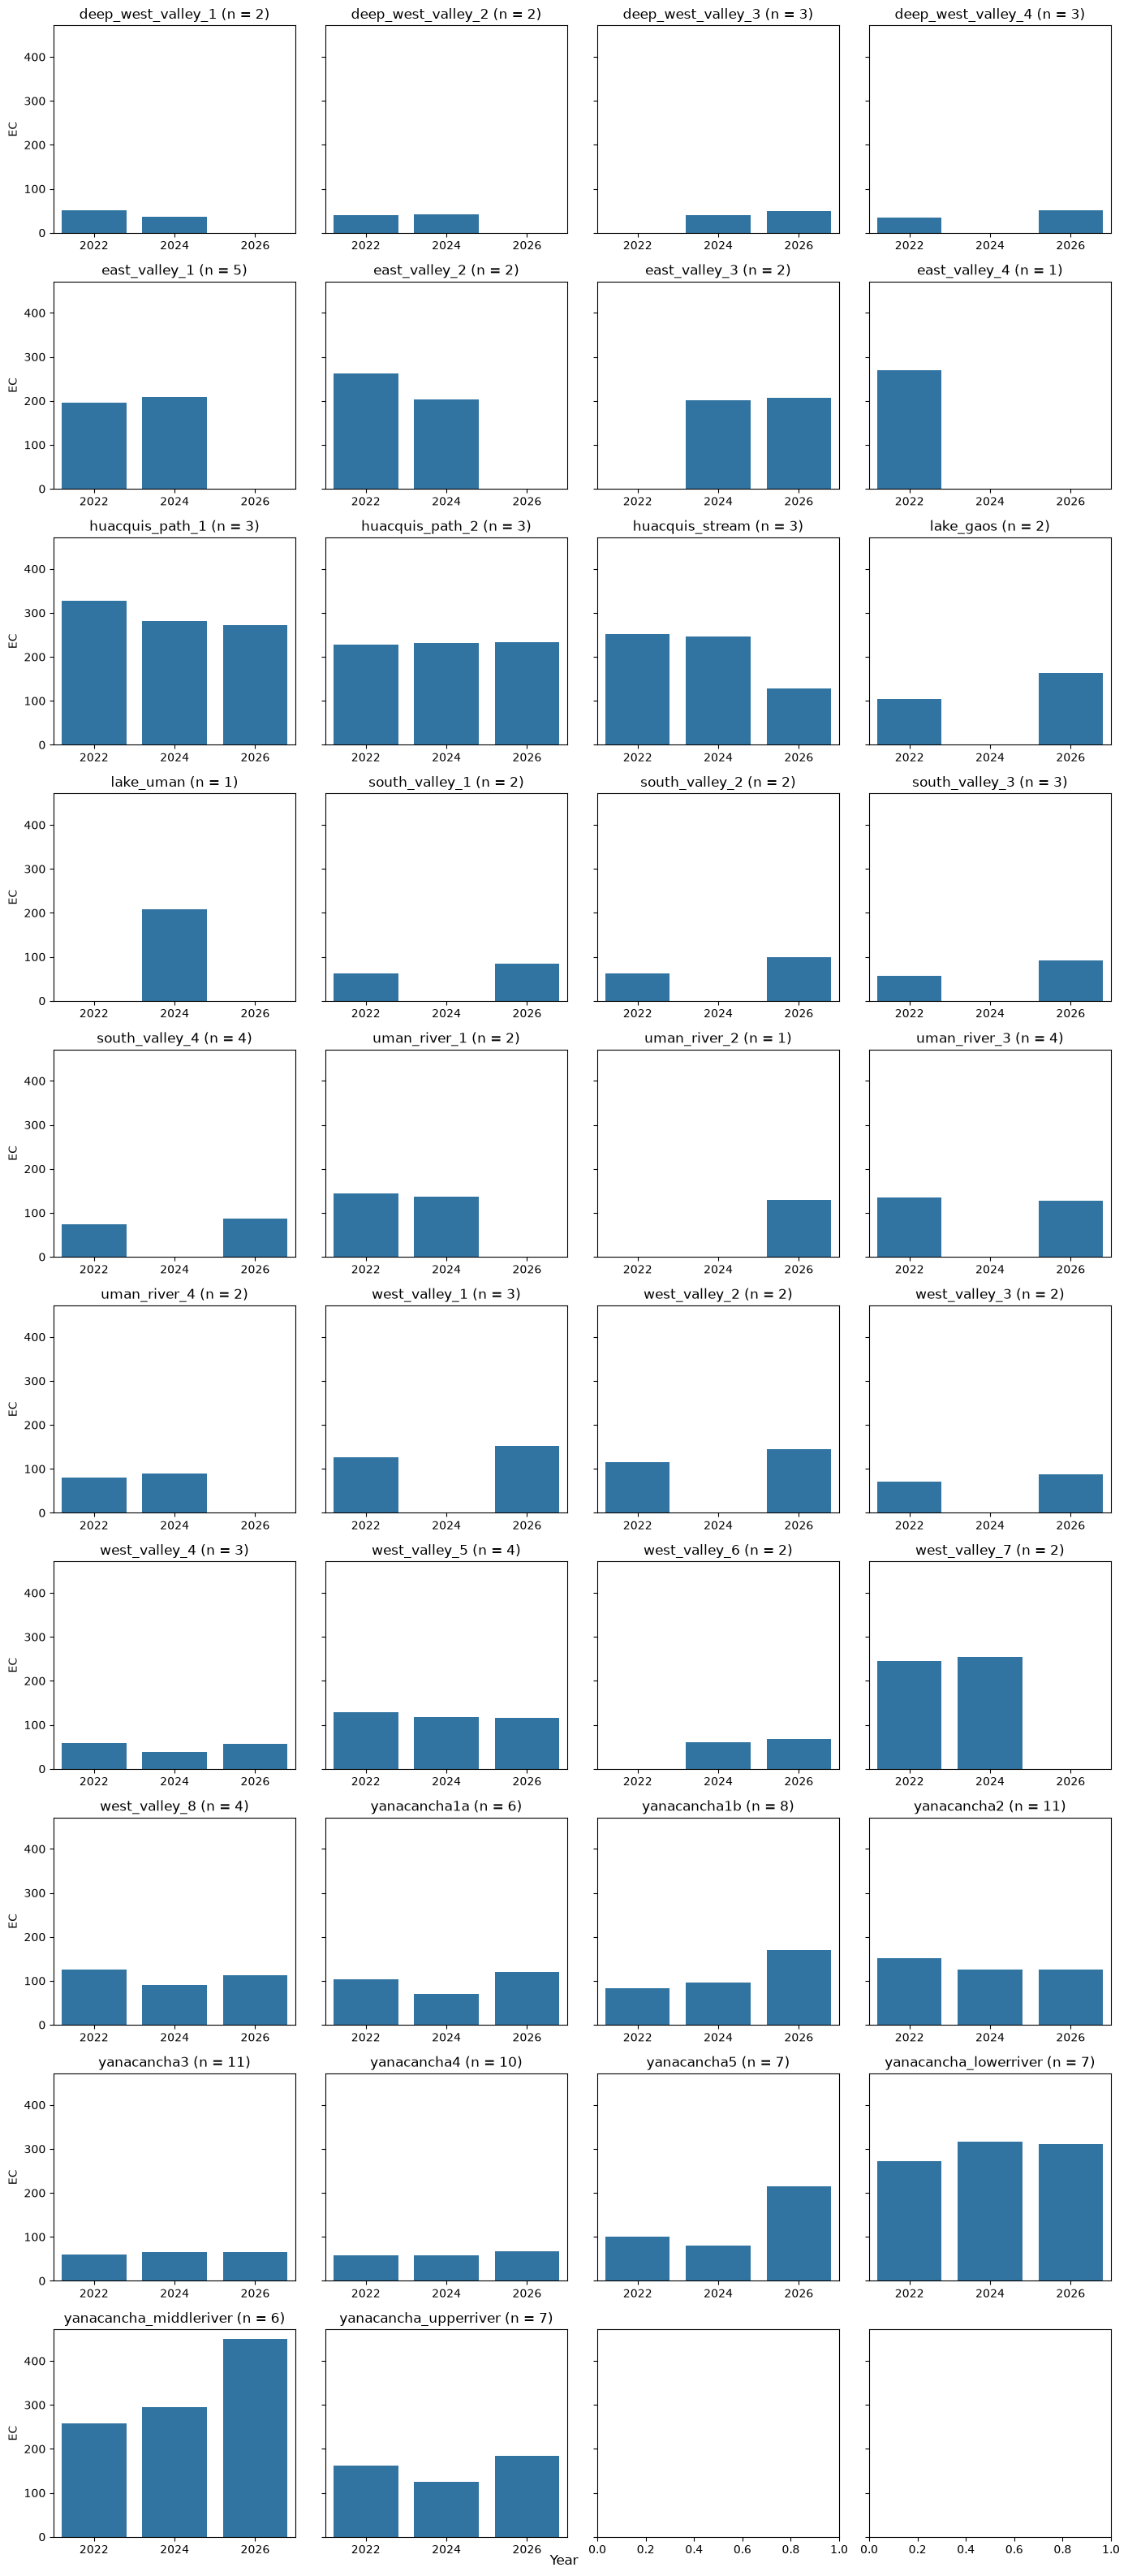

In [211]:
years = sorted(df_summary_comparison['year'].unique())
areas = sorted(df_summary_comparison['group'].unique())

ncols = 4
nrows = math.ceil(len(areas) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(3.5 * ncols, 3.2 * nrows),
                         sharey=True, squeeze=False)
axes = axes.flat

for ax, area in zip(axes, areas):
    df_area = df_summary_comparison[df_summary_comparison['group'] == area]
    n = int(df_area['count_EC'].sum())

    sns.barplot(data=df_area, x='year', y='mean_EC', order=years,
                errorbar=None, ax=ax)

    df_area_by_year = df_area.set_index('year').reindex(years)
    '''
    ax.errorbar(range(len(years)), df_area_by_year['mean_pH'],
                yerr=df_area_by_year['std_pH'],
                fmt='none', color='black', capsize=4)
    '''

    ax.set_title(f'{area} (n = {n})')
    ax.set_xlabel('')
    ax.set_ylabel('')

# hide unused axes in the last row
for ax in list(axes)[len(areas):]:
    ax.set_visible(False)

# label only the first column
for ax in fig.axes[::ncols]:
    ax.set_ylabel('EC')

fig.supxlabel('Year')
plt.tight_layout()
plt.show()

In [198]:
gdf_2026.columns

Index(['GlobalID', 'CreationDate', 'Creator', 'EditDate', 'Editor',
       'Additional_notes', 'tree_cover', 'shrub_cover', 'succulent_cover',
       'grass_cover', 'herbaceous_cover', 'bare_cover', 'Temp', 'EC', 'pH',
       'ID', 'Date_and_time', 'geometry', 'Al', 'As', 'Ba', 'Ca', 'Cd', 'Cu',
       'Fe', 'K', 'Mg', 'Na', 'Pb', 'S', 'measured_vegetation', 'label',
       'low_cover', 'high_cover'],
      dtype='str')

In [240]:
# I want to make multilinear regression models that use vegetation cover
# as the dependent variables, and EC/pH as the independent variables
df_veg_modelling = gdf_2026[['ID', 'EC', 'pH', 'bare_cover', 'low_cover', 'high_cover']].copy()

# tons of columns don't have any values for vegetation
df_veg_modelling = df_veg_modelling.dropna()
df_veg_modelling

,ID,EC,pH,bare_cover,low_cover,high_cover
0,101,145.0,7.93,64.0,34.0,24.0
2,105,121.0,8.34,25.0,71.0,38.0
5,108,115.0,7.91,63.0,28.0,15.0
6,124,118.0,3.84,11.0,64.0,0.0
16,110,113.0,7.83,16.0,75.0,40.0
19,111,229.0,7.83,15.0,86.0,0.0
22,116,99.0,7.39,7.0,93.0,0.0
61,102,129.0,8.03,7.0,70.0,71.0
63,178,133.0,8.28,18.0,78.0,17.0
72,182,132.0,7.89,59.0,40.0,4.0


In [257]:
# the above doesn't include all vegetation samples, there were some in a notebook
# i had to add later...
df_notebook_samples = pd.read_csv('notebook_samples_peru_2026.csv')
# i missed a couple of squares when filling the excel, they should be 0s
df_notebook_samples = df_notebook_samples.fillna(0)
df_notebook_samples

,sample,EC,pH,bare_cover,trees,shrubs,herbs,suc
0,117,99,7.79,14,0,3,84,0.0
1,118,75,7.50,3,0,6,95,0.0
2,122,94,7.71,5,41,12,87,0.0
3,135,220,7.87,50,43,34,53,0.0
4,137,304,8.05,23,0,39,59,0.0
5,141,449,8.23,50,0,0,60,0.0
6,152,180,7.10,0,0,0,99,6.0
7,184,127,8.23,16,0,7,91,1.0


In [258]:
df_notebook_samples['low_cover'] = (
    df_notebook_samples['herbs']
    + df_notebook_samples['suc']
)

df_notebook_samples['high_cover'] = (
    df_notebook_samples['trees']
    + df_notebook_samples['shrubs']
)

# we won't be needing these for our model
df_notebook_samples = df_notebook_samples.drop(
    [	
        'trees', 
        'shrubs', 
        'herbs',	
        'suc'
    ], 
    axis=1
)

df_notebook_samples

,sample,EC,pH,bare_cover,low_cover,high_cover
0,117,99,7.79,14,84.0,3
1,118,75,7.50,3,95.0,6
2,122,94,7.71,5,87.0,53
3,135,220,7.87,50,53.0,77
4,137,304,8.05,23,59.0,39
5,141,449,8.23,50,60.0,0
6,152,180,7.10,0,105.0,0
7,184,127,8.23,16,92.0,7


In [245]:
# let's check if we have the same samples twice in each dataset
set(df_veg_modelling['ID']).intersection(
    set(df_notebook_samples['sample'])
)

set()

empty set = no overlap. great!

In [263]:
df_veg_modelling_full = pd.concat([df_notebook_samples, df_veg_modelling])
df_veg_modelling_full = df_veg_modelling_full.drop(['ID', 'sample'], axis=1)
df_veg_modelling_full

,EC,pH,bare_cover,low_cover,high_cover
0,99.0,7.79,14.0,84.0,3.0
1,75.0,7.50,3.0,95.0,6.0
2,94.0,7.71,5.0,87.0,53.0
3,220.0,7.87,50.0,53.0,77.0
4,304.0,8.05,23.0,59.0,39.0
5,449.0,8.23,50.0,60.0,0.0
6,180.0,7.10,0.0,105.0,0.0
7,127.0,8.23,16.0,92.0,7.0
0,145.0,7.93,64.0,34.0,24.0
2,121.0,8.34,25.0,71.0,38.0


In [264]:
# let's drop bare_cover because it's obviously highly colinear with high
# and low cover values
df_veg_modelling_full = df_veg_modelling_full.drop('bare_cover', axis=1)